# LeafRust AI
### Rust Spot Detection in Plant Leaves

**INSA Summer Camp · Computer Vision Project**

**Project objective:** Develop an object-detection prototype that identifies and highlights visible rust-like regions in plant leaf images.

| Dataset | Model | Output |
|---|---|---|
| 48 annotated leaf images · 229 labeled rust regions | YOLO11n · transfer learning | Bounding boxes, detection status, model weights, and a web demo |

**Dataset partition:** 34 training · 8 validation · 6 test images. All images in this initial dataset contain annotated rust; no verified healthy images are included yet.

*Project status: Experimental prototype. A result with no detections does not confirm that a plant is healthy.*


## 01 · Environment

Python dependencies and hardware configuration.


In [1]:
%pip -q install "ultralytics>=8.3,<9" "gradio>=5,<7" Pillow

import torch
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU selected. Training on CPU may be slow. Enable a GPU in Runtime settings if one is available.")


PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


## 02 · Dataset

Import the curated YOLO-format dataset and verify its structure.


In [2]:
from google.colab import files
from pathlib import Path
from zipfile import ZipFile

uploaded = files.upload()  # select INSA_leaf_rust_48_ready.zip
assert "INSA_leaf_rust_48_ready.zip" in uploaded, "Upload the file INSA_leaf_rust_48_ready.zip"
zip_path = Path('/content/INSA_leaf_rust_48_ready.zip')
with ZipFile(zip_path) as z:
    # The ZIP was prepared here and should contain leaf_rust_data/ only.
    assert all((n.startswith('leaf_rust_data/') and '..' not in Path(n).parts) for n in z.namelist())
    z.extractall('/content')
ROOT = Path('/content/leaf_rust_data')
YAML = ROOT / 'data.yaml'
assert YAML.is_file(), "Missing data.yaml after extraction"
for part in ('train', 'val', 'test'):
    imgs = list((ROOT/'images'/part).glob('*.jpg'))
    labels = list((ROOT/'labels'/part).glob('*.txt'))
    print(part, len(imgs), 'images', len(labels), 'labels')
    assert len(imgs) == len(labels), f"Image/label mismatch in {part}"
print('Dataset ready:', YAML)


Saving INSA_leaf_rust_48_ready.zip to INSA_leaf_rust_48_ready.zip
train 34 images 34 labels
val 8 images 8 labels
test 6 images 6 labels
Dataset ready: /content/leaf_rust_data/data.yaml


## 03 · Model Training

Fine-tune pretrained YOLO11 nano weights on the rust annotations.


In [3]:
from ultralytics import YOLO

model = YOLO('yolo11n.pt')
result = model.train(
    data=str(YAML),
    epochs=50,
    imgsz=768,
    batch=4,
    patience=12,
    device=0 if torch.cuda.is_available() else 'cpu',
    workers=2,
    seed=42,
    project='/content/rust_runs',
    name='first_prototype',
    exist_ok=True,
    plots=True,
)
BEST = Path('/content/rust_runs/first_prototype/weights/best.pt')
assert BEST.exists(), 'No best.pt found; check training output.'
print('Trained weights:', BEST)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/leaf_rust_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

## 04 · Model Evaluation

Evaluate the trained detector using the six held-out test images. Metrics on this small test set have high uncertainty.


In [4]:
trained = YOLO(str(BEST))
metrics = trained.val(data=str(YAML), split='test', imgsz=768, plots=True)
print('Test mAP50:', round(float(metrics.box.map50),4))
print('Test mAP50-95:', round(float(metrics.box.map),4))


Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3579.1±635.4 MB/s, size: 302.1 KB)
val: Scanning /content/leaf_rust_data/labels/test... 6 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6 1.8Kit/s 0.0s
val: New cache created: /content/leaf_rust_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.8it/s 0.3s
                   all          6         32    0.00167     0.0938   0.000205   3.26e-05
Speed: 0.5ms preprocess, 8.6ms inference, 0.0ms loss, 11.7ms postprocess per image
Results saved to /content/runs/detect/val
Test mAP50: 0.0002
Test mAP50-95: 0.0


## 05 · Prediction Visualization

Display a sample test image with predicted rust regions.


Test file: new_rust_1006.jpg | predicted boxes: 50


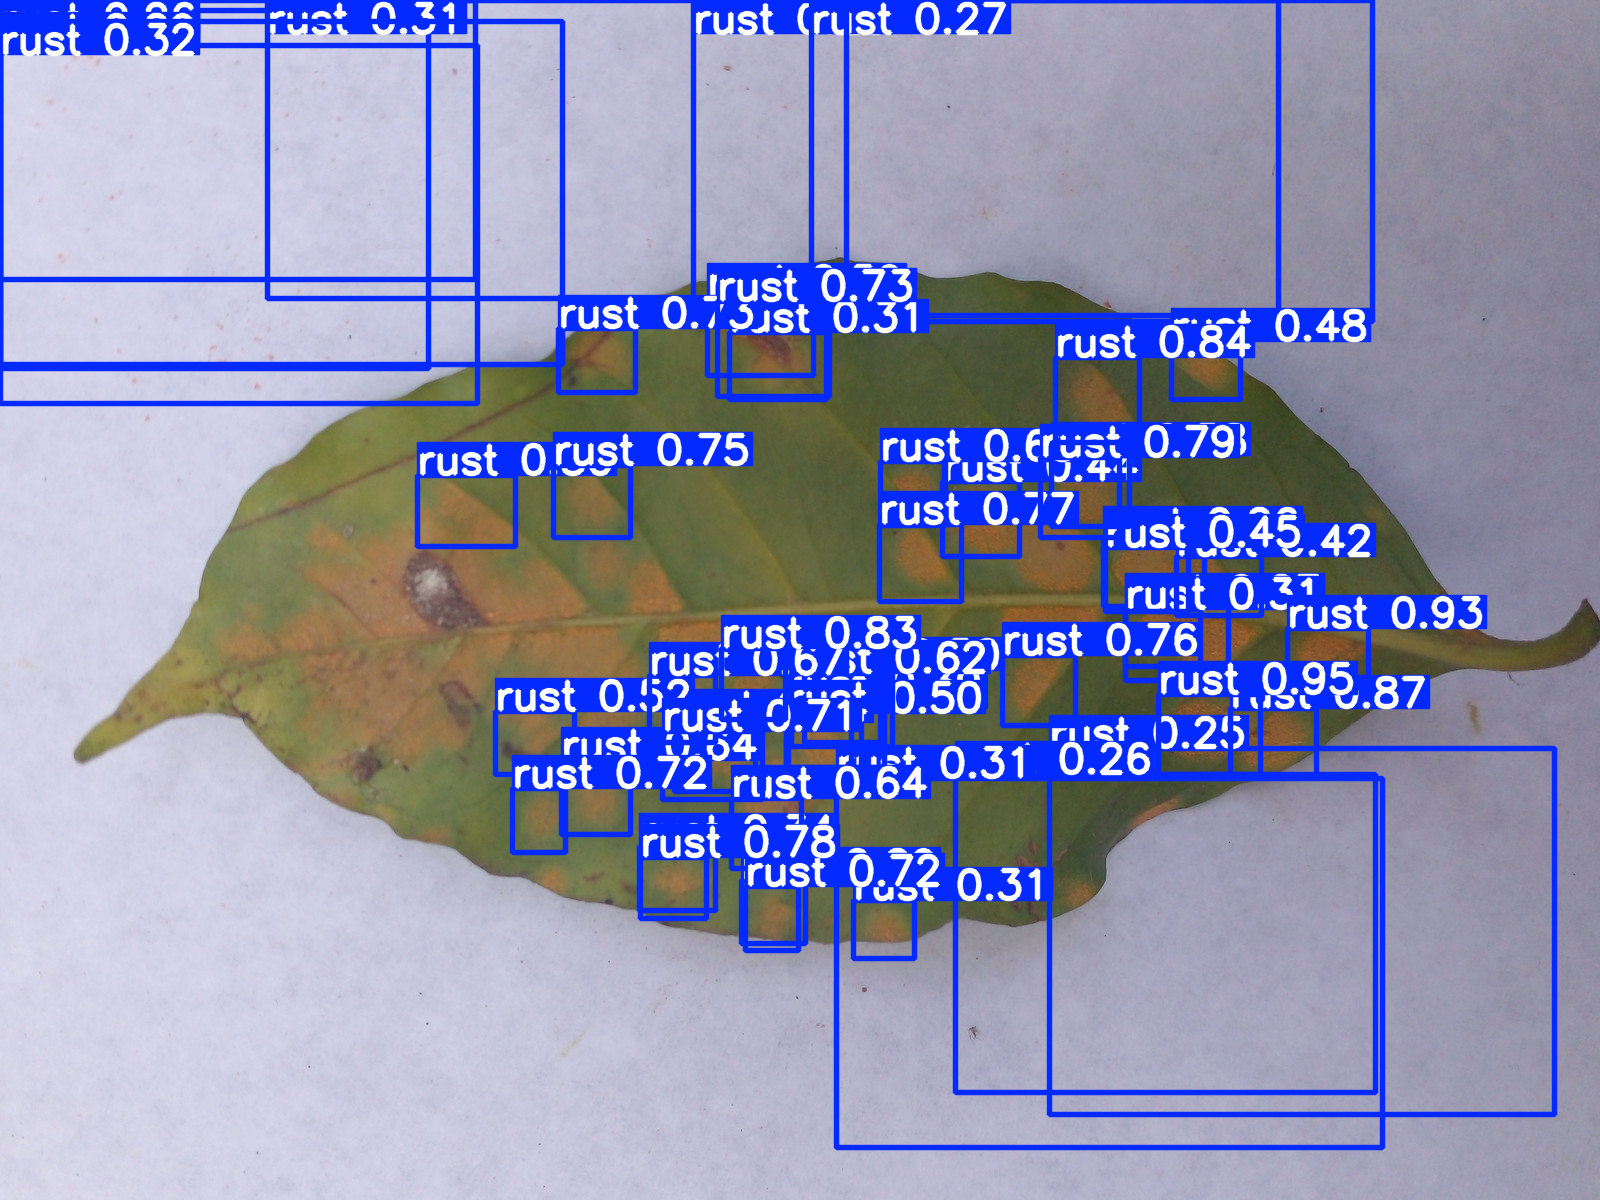

In [5]:
from PIL import Image
from IPython.display import display

test_image = sorted((ROOT/'images'/'test').glob('*.jpg'))[0]
prediction = trained.predict(source=str(test_image), imgsz=768, conf=0.25, verbose=False)[0]
print('Test file:', test_image.name, '| predicted boxes:', len(prediction.boxes))
display(Image.fromarray(prediction.plot()[..., ::-1]))  # YOLO result BGR -> RGB


## 06 · Model Export

Save the trained model artifact (`best.pt`) for deployment and version control.


In [6]:
from google.colab import files
files.download(str(BEST))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 07 · Interactive Web Demo

An upload interface for visualizing predictions and reporting whether rust-like regions were detected. The temporary Gradio sharing link requires an active Colab runtime.


In [ ]:
import gradio as gr
from PIL import Image, ImageDraw, ImageOps

infer_model = YOLO(str(BEST))

def assess_leaf(image, threshold):
    if image is None:
        return None, 'Please upload a leaf image.'
    im = ImageOps.exif_transpose(image).convert('RGB')
    out = infer_model.predict(source=im, conf=float(threshold), imgsz=768, verbose=False)[0]
    canvas = im.copy()
    pen = ImageDraw.Draw(canvas)
    scores = []
    for box in out.boxes:
        if int(box.cls.item()) != 0:
            continue
        coords = tuple(int(x) for x in box.xyxy[0].tolist())
        confidence = float(box.conf.item())
        pen.rectangle(coords, outline='red', width=max(3, im.width // 500))
        scores.append(confidence)
    if scores:
        note = f'Rust detected: {len(scores)} region(s). Max confidence: {max(scores):.1%}. Prototype only.'
    else:
        note = 'No rust detected at this threshold. This does NOT mean the leaf is healthy.'
    return canvas, note

demo = gr.Interface(
    fn=assess_leaf,
    inputs=[gr.Image(type='pil', label='Upload a leaf'), gr.Slider(0.05,0.9,value=0.25,step=0.05,label='Confidence')],
    outputs=[gr.Image(type='pil', label='Predicted rust areas'),gr.Textbox(label='Result')],
    title='INSA Leaf Rust Detector — Prototype',
    description='Experimental model based on 48 infected leaf images. Predictions require human review.',
)
demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://9d3cb5c0ac52fd99b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 08 · Future Development

- **Annotation quality:** Correct misplaced boxes and annotate currently missed rust regions.
- **Data diversity:** Include verified healthy leaves and images captured under different lighting and backgrounds.
- **Model reliability:** Evaluate on an independent, larger test set before claiming accurate detection.
- **Deployment:** Package the trained model, interface, methodology, and test results in the GitHub repository.

**References:** [Ultralytics documentation](https://docs.ultralytics.com/modes/train) · [Gradio documentation](https://www.gradio.app/docs/gradio/image)

*Dataset ethics: Share source images publicly only when permitted.*
